In [1]:
from google.colab import files
files.upload()
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [2]:
import kagglehub
import shutil

# Download latest version
path = kagglehub.dataset_download("emmarex/plantdisease")
destination = "/content/plantdisease"
shutil.copytree(path, destination, dirs_exist_ok=True)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'plantdisease' dataset.
Path to dataset files: /kaggle/input/plantdisease


In [3]:
ls "/content/plantdisease/PlantVillage"

Pepper__bell___Bacterial_spot/  Tomato_Late_blight/
Pepper__bell___healthy/         Tomato_Leaf_Mold/
Potato___Early_blight/          Tomato_Septoria_leaf_spot/
Potato___healthy/               Tomato_Spider_mites_Two_spotted_spider_mite/
Potato___Late_blight/           Tomato__Target_Spot/
Tomato_Bacterial_spot/          Tomato__Tomato_mosaic_virus/
Tomato_Early_blight/            Tomato__Tomato_YellowLeaf__Curl_Virus/
Tomato_healthy/


In [4]:
import os

DATA_DIR = "/content/plantdisease/PlantVillage"

for folder in sorted(os.listdir(DATA_DIR)):
    if folder.startswith("Tomato"):
        print(folder, "=", len(os.listdir(os.path.join(DATA_DIR, folder))), "images")

Tomato_Bacterial_spot = 2127 images
Tomato_Early_blight = 1000 images
Tomato_Late_blight = 1909 images
Tomato_Leaf_Mold = 952 images
Tomato_Septoria_leaf_spot = 1771 images
Tomato_Spider_mites_Two_spotted_spider_mite = 1676 images
Tomato__Target_Spot = 1404 images
Tomato__Tomato_YellowLeaf__Curl_Virus = 3209 images
Tomato__Tomato_mosaic_virus = 373 images
Tomato_healthy = 1591 images


In [5]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [6]:
# transforming the images so that they have the same dimensions
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [ ]:
from PIL import Image, UnidentifiedImageError

class TomatoDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.images = []
        skipped = 0

        for folder in sorted(os.listdir(root_dir)):
            if not folder.startswith("Tomato"):
                continue
            label = 0 if folder == "Tomato_healthy" else 1
            folder_path = os.path.join(root_dir, folder)
            for filename in sorted(os.listdir(folder_path)):
                image_path = os.path.join(folder_path, filename)
                try:
                    with Image.open(image_path) as img:
                        img.verify()
                    self.images.append((image_path, label))
                except (UnidentifiedImageError, OSError, ValueError):
                    skipped += 1
        print("Valid images:", len(self.images))
        print("Skipped invalid files:", skipped)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_path, label = self.images[index]
        with Image.open(image_path) as img:
            image = img.convert("RGB")
        if self.transform:
            image = self.transform(image)

        return image, label

In [8]:
dataset = TomatoDataset(DATA_DIR, transform=transform)

print("Total valid image paths:", len(dataset))

train_labels = [label for _, label in dataset.images]
indices = np.arange(len(dataset))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=train_labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=[train_labels[i] for i in temp_idx]
)

train_loader = DataLoader(
    Subset(dataset, train_idx),
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    Subset(dataset, val_idx),
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    Subset(dataset, test_idx),
    batch_size=32,
    shuffle=False
)

print("Rebuilt all DataLoaders!")

Valid images: 16011
Skipped invalid files: 1
Total valid image paths: 16011
Rebuilt all DataLoaders!


In [9]:
images, labels = next(iter(train_loader))
print(images.shape, labels.shape)

torch.Size([32, 3, 128, 128]) torch.Size([32])


In [ ]:
net = nn.Sequential(
    nn.Conv2d(3, 16, 3),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.LazyLinear(2)
).to(device)

sample_images, _ = next(iter(train_loader))
output = net(sample_images.to(device))

print("Output shape:", output.shape)

Output shape: torch.Size([32, 2])


In [ ]:
# get labels for training samples
train_targets = [
    dataset.images[i][1]
    for i in train_idx
]

# count samples in each class
class_counts = np.bincount(train_targets, minlength=2)

# calculate class weights
class_weights = len(train_targets) / (2 * class_counts)

weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

# weighted loss
loss_fn = nn.CrossEntropyLoss(weight=weights)

# optimizer
optimizer = optim.Adam(net.parameters(), lr=0.001)

print("Class counts:", class_counts)
print("Class weights:", weights)

Class counts: [ 1114 10093]
Class weights: tensor([5.0301, 0.5552], device='cuda:0')


In [ ]:
epochs = 10

for epoch in range(epochs):
    net.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = net(images)
        loss = loss_fn(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        predictions = torch.argmax(outputs, dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
    train_accuracy = 100 * correct / total
    average_loss = running_loss / len(train_loader)

    # Validation
    net.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = net(images)
            predictions = torch.argmax(outputs, dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)
    val_accuracy = 100 * val_correct / val_total
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {average_loss:.4f} "
        f"Train Accuracy: {train_accuracy:.2f}% "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/10] Loss: 0.1531 Train Accuracy: 94.38% Validation Accuracy: 98.88%
Epoch [2/10] Loss: 0.0615 Train Accuracy: 98.13% Validation Accuracy: 99.38%
Epoch [3/10] Loss: 0.0594 Train Accuracy: 98.00% Validation Accuracy: 98.29%
Epoch [4/10] Loss: 0.0235 Train Accuracy: 99.15% Validation Accuracy: 98.92%
Epoch [5/10] Loss: 0.0245 Train Accuracy: 99.19% Validation Accuracy: 98.71%
Epoch [6/10] Loss: 0.0296 Train Accuracy: 99.05% Validation Accuracy: 88.84%
Epoch [7/10] Loss: 0.0365 Train Accuracy: 98.76% Validation Accuracy: 99.42%
Epoch [8/10] Loss: 0.0069 Train Accuracy: 99.79% Validation Accuracy: 99.67%
Epoch [9/10] Loss: 0.0222 Train Accuracy: 99.30% Validation Accuracy: 99.17%
Epoch [10/10] Loss: 0.0149 Train Accuracy: 99.56% Validation Accuracy: 99.58%


              precision    recall  f1-score   support

     Healthy     0.9791    0.9832    0.9811       238
    Diseased     0.9982    0.9977    0.9979      2164

    accuracy                         0.9963      2402
   macro avg     0.9886    0.9904    0.9895      2402
weighted avg     0.9963    0.9963    0.9963      2402



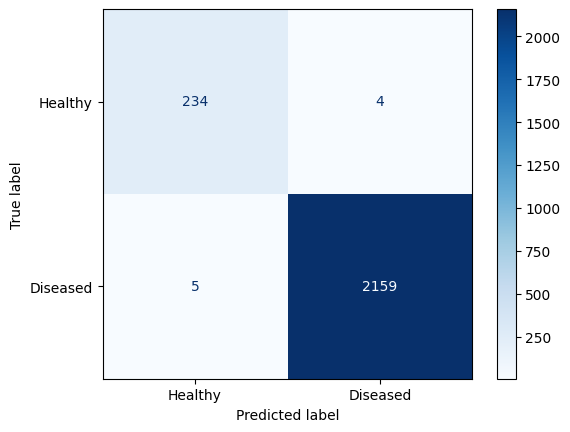

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

net.eval()

all_preds = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:
        images = images.to(device)
        outputs = net(images)
        predictions = torch.argmax(outputs, dim=1)
        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_preds,
    target_names=["Healthy", "Diseased"],
    digits=4
))

cm = confusion_matrix(all_labels, all_preds)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "Diseased"]
).plot(cmap="Blues")

plt.show()